# China macro regimes and fixed-income-plus
## V2 research walkthrough

This notebook reads the saved out-of-sample results and reproduces ten exhibits from the V2 pipeline. Run from the repository root with the existing local datasets and virtual environment.

```powershell
.\.venv\Scripts\python.exe run_pipeline.py --stage all
.\.venv\Scripts\python.exe -m pytest -q
.\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace notebooks/01_MultiAsset_Research_Walkthrough.ipynb
```

The cells accept the repository root or the notebooks directory as the working directory. Returns and weights are stored as decimals. Archive figures are reported explicitly as V1 comparisons.

In [1]:
from pathlib import Path
from io import BytesIO
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage

here = Path.cwd().resolve()
root = next((path for path in (here, *here.parents)
             if (path / "configs" / "strategy_config.yaml").is_file()), None)
if root is None:
    raise FileNotFoundError("Open the notebook from the repository or notebooks directory.")
outputs = root / "outputs"
if not (outputs / "run_metadata.json").is_file():
    raise FileNotFoundError("Run python run_pipeline.py --stage all from the repository root.")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.analytics.visualization import FIGURE_FILES, MODELS, generate_figures

figures = root / "reports" / "figures"
if any(not (figures / filename).exists() for filename in FIGURE_FILES.values()):
    generate_figures(outputs, figures)

def read(table, **kwargs):
    return pd.read_csv(outputs / (table + ".csv"), **kwargs)

def show_figure(key):
    with PILImage.open(figures / FIGURE_FILES[key]) as original:
        preview = original.convert("RGB")
        preview.thumbnail((1450, 1200), PILImage.Resampling.LANCZOS)
        buffer = BytesIO()
        preview.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue(), width=min(preview.width, 1080)))

meta = json.loads((outputs / "run_metadata.json").read_text(encoding="utf-8"))
display(pd.Series({key: meta[key] for key in [
    "first_session", "last_session", "sessions", "annualization_sessions",
    "allocation_trials_for_dsr",
]}, name="Run metadata").to_frame())

,Run metadata
first_session,2018-01-02
last_session,2026-11-20
sessions,2155
annualization_sessions,252
allocation_trials_for_dsr,20


## 1. Six primary allocation models

The 20/80 portfolio is the fixed-income-plus comparison baseline. The other models show what changes when the allocation rule uses capital weights, risk contributions, clusters, trailing ERP, or Black–Litterman views. Sharpe uses the local money-market ETF as the cash proxy. Drawdown is signed and includes the initial investment as the first peak.

V2 Black–Litterman uses strategic core-invested weights and bond-relative views. Cash enters through implementation and risk controls. The overlay uses a trailing 252-session peak and scales equity and convertibles, with released risk weight allocated to the bond sleeve and cash. Reported drawdown in the exhibit still uses an inception-to-date peak.

,cagr,annualized_volatility,sharpe,max_drawdown,deflated_sharpe_probability,sharpe_ci_low,sharpe_ci_high
strategy,,,,,,,
Macro_BL_FixedIncomePlus,4.20%,3.38%,0.76,-3.93%,72.3%,0.12,1.38
Static_20_80,3.79%,3.75%,0.58,-4.51%,53.3%,-0.04,1.19
Static_60_40,3.02%,11.43%,0.18,-24.08%,13.4%,-0.46,0.79
Risk_Parity_ERC,4.15%,2.99%,0.84,-3.71%,79.1%,0.22,1.45
HRP,4.07%,1.34%,1.79,-1.87%,100.0%,0.94,2.57
ERP_Tactical_20_80,4.80%,4.49%,0.71,-5.95%,67.7%,-0.01,1.40


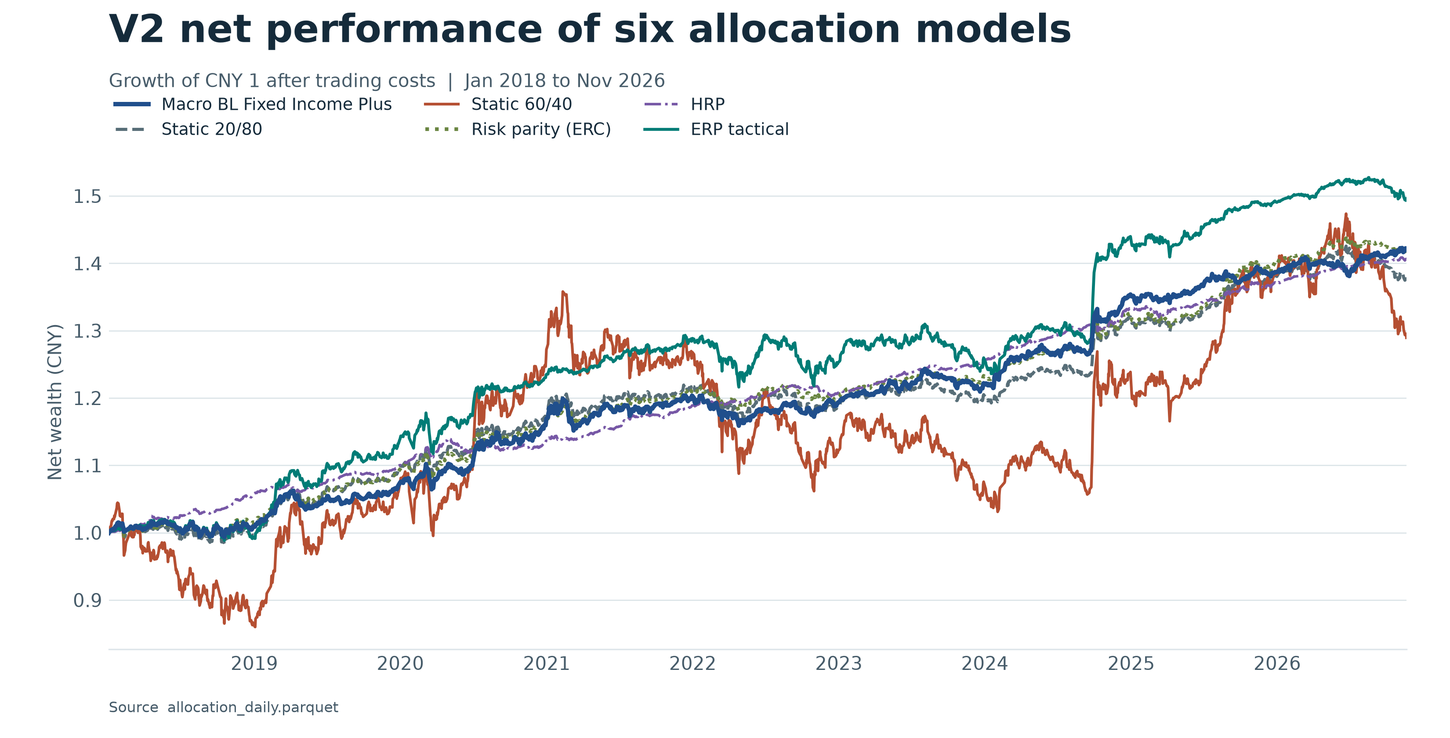

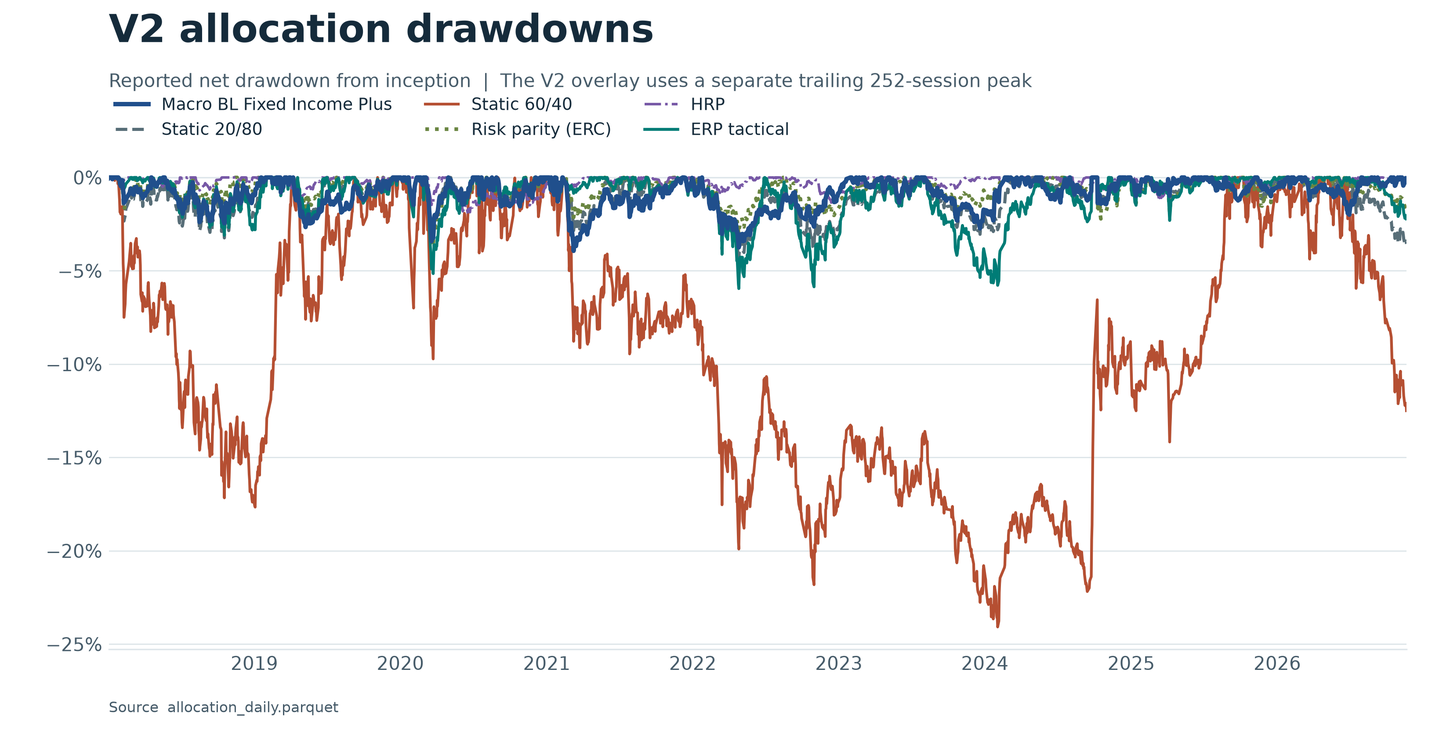

In [2]:
performance = read("performance_summary", index_col="strategy")
headline_formats = {
    "cagr": "{:.2%}", "annualized_volatility": "{:.2%}", "sharpe": "{:.2f}",
    "max_drawdown": "{:.2%}", "deflated_sharpe_probability": "{:.1%}",
    "sharpe_ci_low": "{:.2f}", "sharpe_ci_high": "{:.2f}",
}
display(performance.loc[list(MODELS), list(headline_formats)].style.format(headline_formats))
show_figure("nav")
show_figure("drawdown")

## 2. Point-in-time Chinese macro regimes

The economic clock bins the trailing growth and inflation signals. The expanding probability model provides a second read on the same states. The chart extends each observed filtered probability forward to the next decision date. The equity risk premium is the CSI 300 earnings yield minus the observable ChinaBond 10-year government yield.

date,rule_regime,filtered_regime,p_Recovery,p_Overheat,p_Stagflation,p_Recession,erp_pct_3y
2026-03-31,Stagflation,Recession,20.4%,23.1%,27.7%,28.8%,11.2%
2026-04-30,Overheat,Overheat,27.1%,40.4%,18.1%,14.4%,0.1%
2026-05-29,Overheat,Overheat,14.7%,54.6%,23.1%,7.6%,2.5%
2026-06-30,Overheat,Overheat,8.9%,56.2%,29.0%,5.8%,5.2%
2026-07-31,Overheat,Overheat,8.4%,48.4%,35.4%,7.8%,8.3%
2026-08-31,Stagflation,Stagflation,5.3%,13.8%,55.3%,25.5%,34.5%
2026-09-30,Overheat,Stagflation,10.7%,35.8%,40.9%,12.7%,43.7%
2026-10-30,Overheat,Overheat,8.4%,53.3%,32.5%,5.8%,63.5%


engine,regime,asset,months,annualized_return,sharpe
rule_regime,Recovery,equity,21,8.29%,0.50
rule_regime,Overheat,equity,24,-7.59%,-0.39
rule_regime,Stagflation,equity,29,-5.42%,-0.24
rule_regime,Recession,equity,32,11.93%,0.52
filtered_regime,Recovery,equity,17,8.27%,0.46
filtered_regime,Overheat,equity,25,-7.51%,-0.40
filtered_regime,Stagflation,equity,27,-8.75%,-0.41
filtered_regime,Recession,equity,37,13.98%,0.62


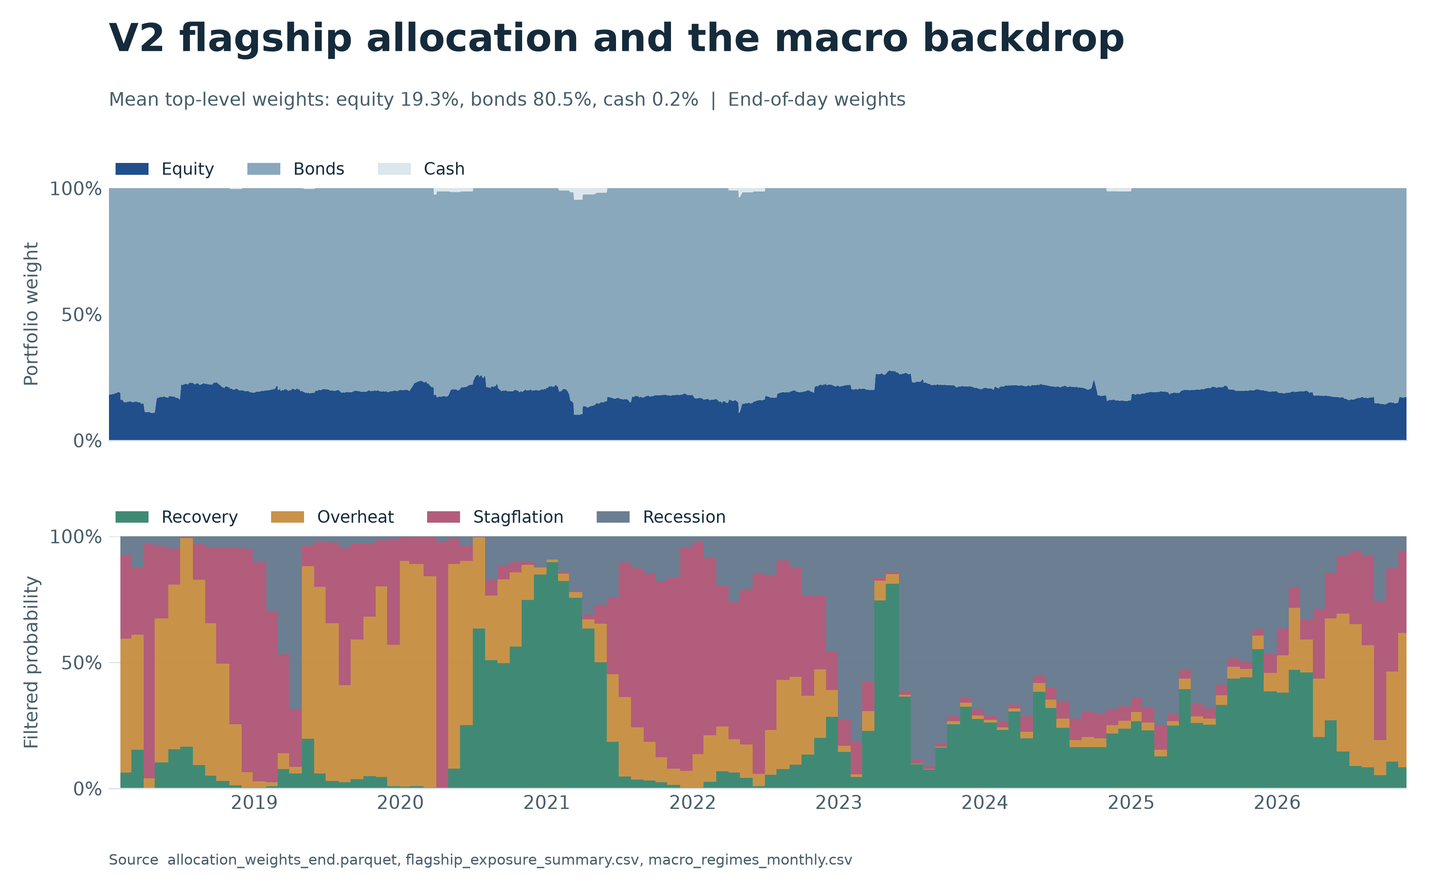

,V1 top level,V2 look-through,V2 top level
equity,15.01%,19.34%,19.34%
bond,16.04%,64.46%,80.46%
cash,68.95%,16.20%,0.20%


In [3]:
flagship = "Macro_BL_FixedIncomePlus"
benchmark = "Static_20_80"
regimes = read("macro_regimes_monthly", parse_dates=["date"])
prob_cols = ["p_Recovery", "p_Overheat", "p_Stagflation", "p_Recession"]
regime_cols = ["date", "rule_regime", "filtered_regime", *prob_cols, "erp_pct_3y"]
study_months = regimes.loc[regimes["date"].between(meta["first_session"], meta["last_session"])]
display(study_months[regime_cols].tail(8).style.hide(axis="index").format(
    {"date": "{:%Y-%m-%d}", **{col: "{:.1%}" for col in [*prob_cols, "erp_pct_3y"]}},
    na_rep="—",
))
display(read("macro_regime_asset_stats").query("asset == 'equity'").style.hide(axis="index").format(
    {"annualized_return": "{:.2%}", "sharpe": "{:.2f}"}, na_rep="—",
))
show_figure("regimes")

exposure = read("flagship_exposure_summary").pivot(index="asset", columns="layer", values="mean_weight")
v1 = json.loads((outputs / "v1_baseline_snapshot.json").read_text(encoding="utf-8"))
exposure_comparison = pd.concat([
    pd.Series(v1["flagship_mean_weights"], name="V1 top level"),
    exposure.rename(columns={"top_level": "V2 top level", "lookthrough": "V2 look-through"}),
], axis=1)
display(exposure_comparison.style.format("{:.2%}", na_rep="—"))

## 3. CSI 300 equity research and static industry proxy

The factor study joins trailing observations to the historical membership and uses industry-and-size residualization. Baostock's latest CSRC industry snapshot supplies first-letter historical sector proxies. Small groups share an OTHER bucket. This retrospective mapping can misclassify historical issuers and can reflect later reclassifications. A point-in-time historical sector table, such as Wind's historical Shenwan classifications, could supply the same join once mapped to the desired sectors.

Ridge and LightGBM train on realized within-month rank-normalized labels in [-1, 1]. Rank IC and investment returns still use the original forward labels. The ensemble shrinks estimates from available out-of-sample Rank IC history toward a prior that favors E1. Portfolio optimization penalizes turnover and caps sector deviations from the modeled CSI 300 benchmark at four percentage points. A constrained execution repair accounts for frozen positions and tradability at the execution close. The diagnostic shows both the approved target and the realized execution close against the same decision benchmark.

,mean_rank_ic,annualized_icir,newey_west_t,ic_win_rate,mean_monthly_long_short
factor,,,,,
real_vol_60d,0.049,0.82,3.04,62.3%,0.05%
idio_vol_60d,0.048,0.98,3.70,64.2%,0.23%
vol_price_corr_20d,0.039,1.10,3.41,59.4%,0.68%
turnover_20d,0.037,0.66,2.34,59.4%,-0.03%
cfp,0.030,0.68,2.29,55.7%,0.23%
bp,0.029,0.53,1.70,57.5%,0.10%
ep_ttm,0.028,0.49,1.84,52.8%,0.12%
rev_20d,0.026,0.58,1.61,50.9%,0.44%
dist_52w_high,0.023,0.45,1.52,66.0%,0.56%


,cagr,sharpe,info_ratio,annualized_cost_bps,annualized_turnover,max_drawdown
strategy,,,,,,
E1_ICIR,9.08%,0.49,0.87,65.1,277.7%,-28.24%
E2_Ridge,2.98%,0.16,0.33,69.6,300.5%,-33.59%
E3_LightGBM,4.91%,0.27,0.52,67.4,290.6%,-35.05%
Equity_Alpha_Sleeve,6.52%,0.36,0.65,59.6,254.5%,-32.17%
Equity_Top50,5.52%,0.30,0.59,96.0,405.9%,-35.88%


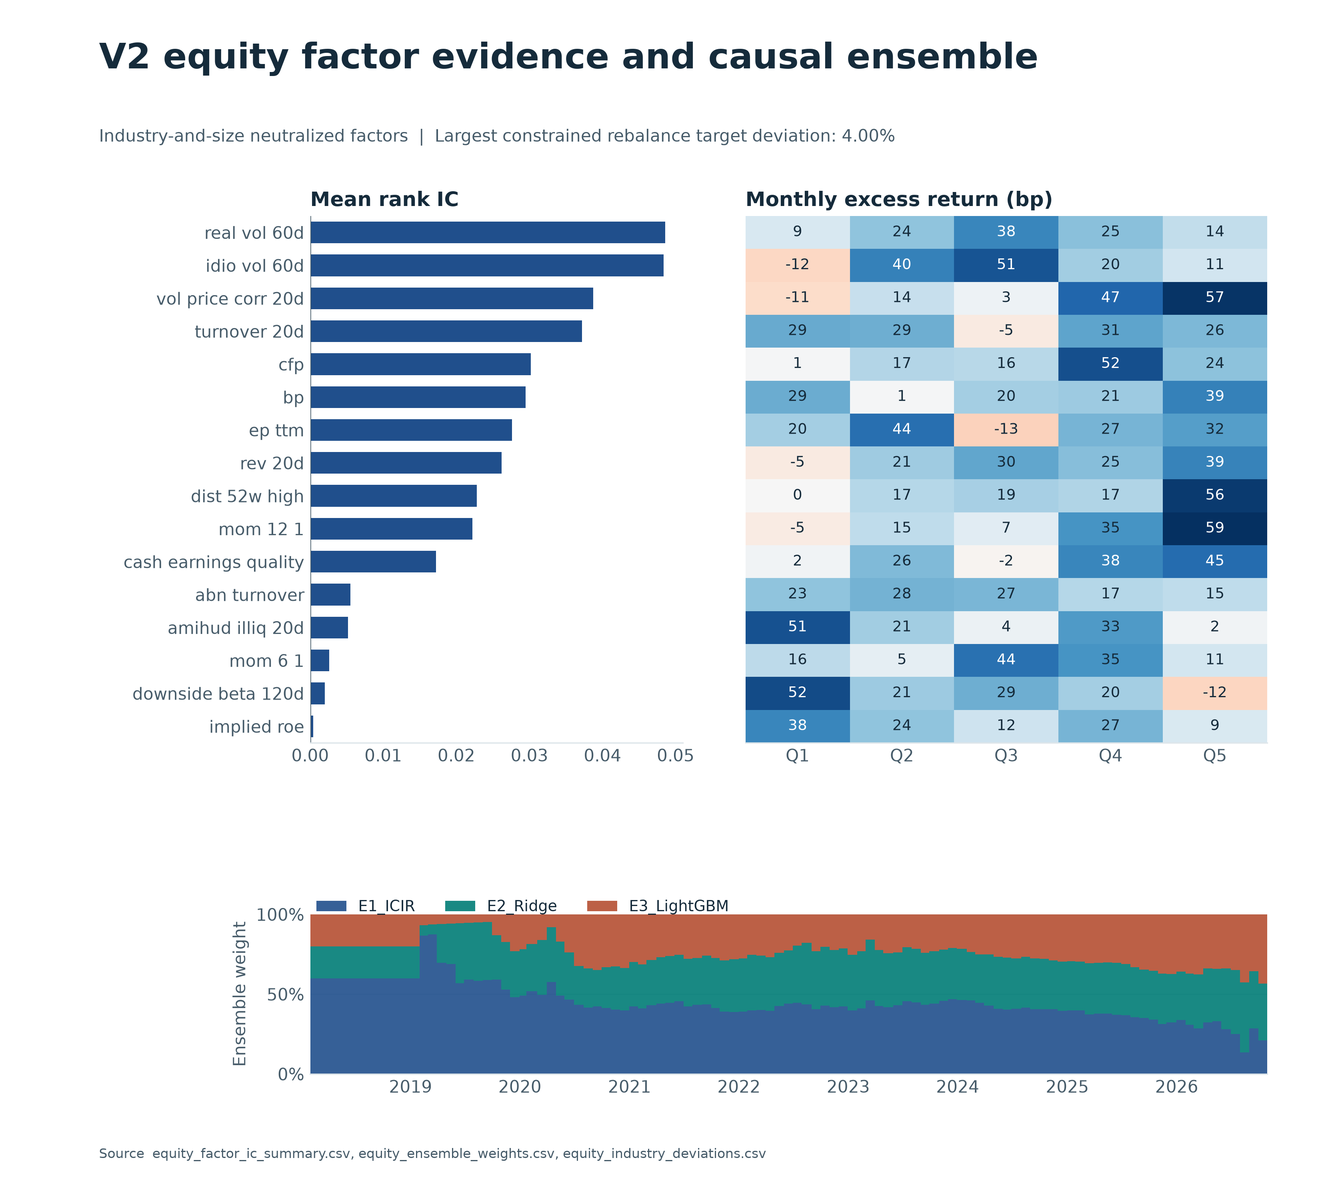

,weight_E1_ICIR,weight_E2_Ridge,weight_E3_LightGBM
mean,44.9%,30.2%,24.8%
min,13.6%,6.3%,4.8%
max,87.4%,43.8%,43.5%


,observations,max_target,max_executed_close
strategy,,,
E1_ICIR,"1,013",4.000%,4.000%
E2_Ridge,"1,011",4.000%,4.000%
E3_LightGBM,"1,031",4.000%,4.000%
Equity_Alpha_Sleeve,"1,013",4.000%,4.000%
Equity_Cost_0.5x,"1,013",4.000%,4.000%
Equity_Cost_2x,"1,013",4.000%,4.000%
Equity_Execution_Delay,"1,073",4.000%,4.000%


,Covered observations,Coverage of eligible observations
Strict point-in-time,0,0.00%
Latest-snapshot proxy,"31,017",98.07%
Used in model,"31,017",98.07%


In [4]:
factors = read("equity_factor_ic_summary").set_index("factor").sort_values("mean_rank_ic", ascending=False)
ic_formats = {
    "mean_rank_ic": "{:.3f}", "annualized_icir": "{:.2f}", "newey_west_t": "{:.2f}",
    "ic_win_rate": "{:.1%}", "mean_monthly_long_short": "{:.2%}",
}
display(factors.loc[:, list(ic_formats)].style.format(ic_formats))
equity_models = ["E1_ICIR", "E2_Ridge", "E3_LightGBM", "Equity_Alpha_Sleeve", "Equity_Top50"]
equity_perf = read("equity_performance", index_col="strategy")
eq_formats = {"cagr": "{:.2%}", "sharpe": "{:.2f}", "info_ratio": "{:.2f}",
              "annualized_cost_bps": "{:.1f}", "annualized_turnover": "{:.1%}",
              "max_drawdown": "{:.2%}"}
display(equity_perf.loc[equity_models, list(eq_formats)].style.format(eq_formats))
show_figure("equity")

ensemble = read("equity_ensemble_weights", parse_dates=["date"]).set_index("date")
ensemble_cols = [f"weight_{name}" for name in equity_models[:3]]
ensemble_oos = ensemble.loc[meta["first_session"]:meta["last_session"], ensemble_cols]
display(ensemble_oos.agg(["mean", "min", "max"]).style.format("{:.1%}"))
industry = read("equity_industry_deviations", parse_dates=["decision_date", "execution_date"])
industry_max = industry.groupby("strategy").agg(
    observations=("abs_deviation", "size"),
    max_target=("abs_deviation", "max"),
    max_executed_close=("executed_abs_deviation", "max"),
)
display(industry_max.style.format({
    "observations": "{:,.0f}", "max_target": "{:.3%}", "max_executed_close": "{:.3%}",
}))
coverage = read("equity_point_in_time_coverage", parse_dates=["date"])
coverage = coverage.loc[coverage["date"].between(meta["first_session"], meta["last_session"])]
coverage_counts = coverage[[
    "industry_pit_known_members", "industry_proxy_known_members", "industry_known_members",
]].sum()
coverage_counts.index = ["Strict point-in-time", "Latest-snapshot proxy", "Used in model"]
display(pd.DataFrame({
    "Covered observations": coverage_counts,
    "Coverage of eligible observations": coverage_counts / coverage["eligible_members"].sum(),
}).style.format({"Covered observations": "{:,}", "Coverage of eligible observations": "{:.2%}"}))

## 4. ChinaBond shape factors and the investable bond sleeve

Nelson–Siegel fits the level, slope and curvature of each government curve. Theoretical constant-duration returns give a pricing diagnostic. The investable sleeve uses official adjusted ETF NAV returns.

V2 anchors neutral duration to the passive bond mix near 5.3 years. Momentum, carry and roll-down, and macro defense inform deviations from that anchor. The tail credit gate combines spread and funding signals and tightens credit and target duration limits. Realized end-of-day weights and duration can drift between executions, so the shaded gate in the chart should be read alongside the realized path.

,Estimate
"PCA first three components, calibration share",98.84%
"PCA first three components, projected OOS share",98.22%
"Median DNS RMSE, OOS (bp)",7.89


theoretical_index,etf,sessions,correlation,mean_daily_residual_bps,annualized_tracking_residual
CGB_1Y,cash,2155,0.13,-0.34,0.43%
CGB_5Y,cgb5,2155,0.94,-0.38,0.69%
CGB_10Y,cgb10,2155,0.95,-0.27,1.03%
MTN_AAA_3Y,credit,2155,0.79,-0.23,0.68%


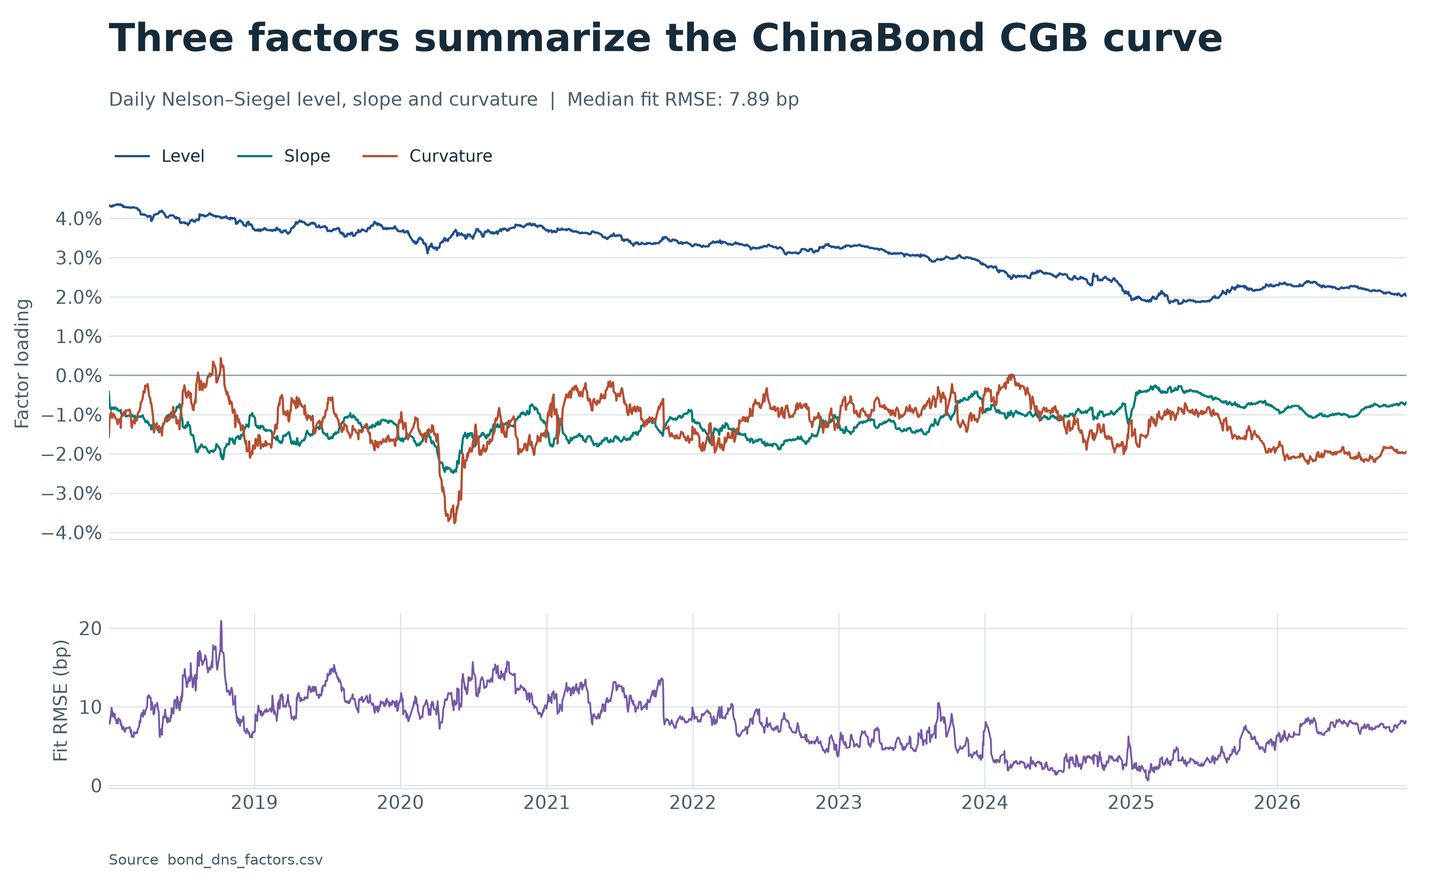

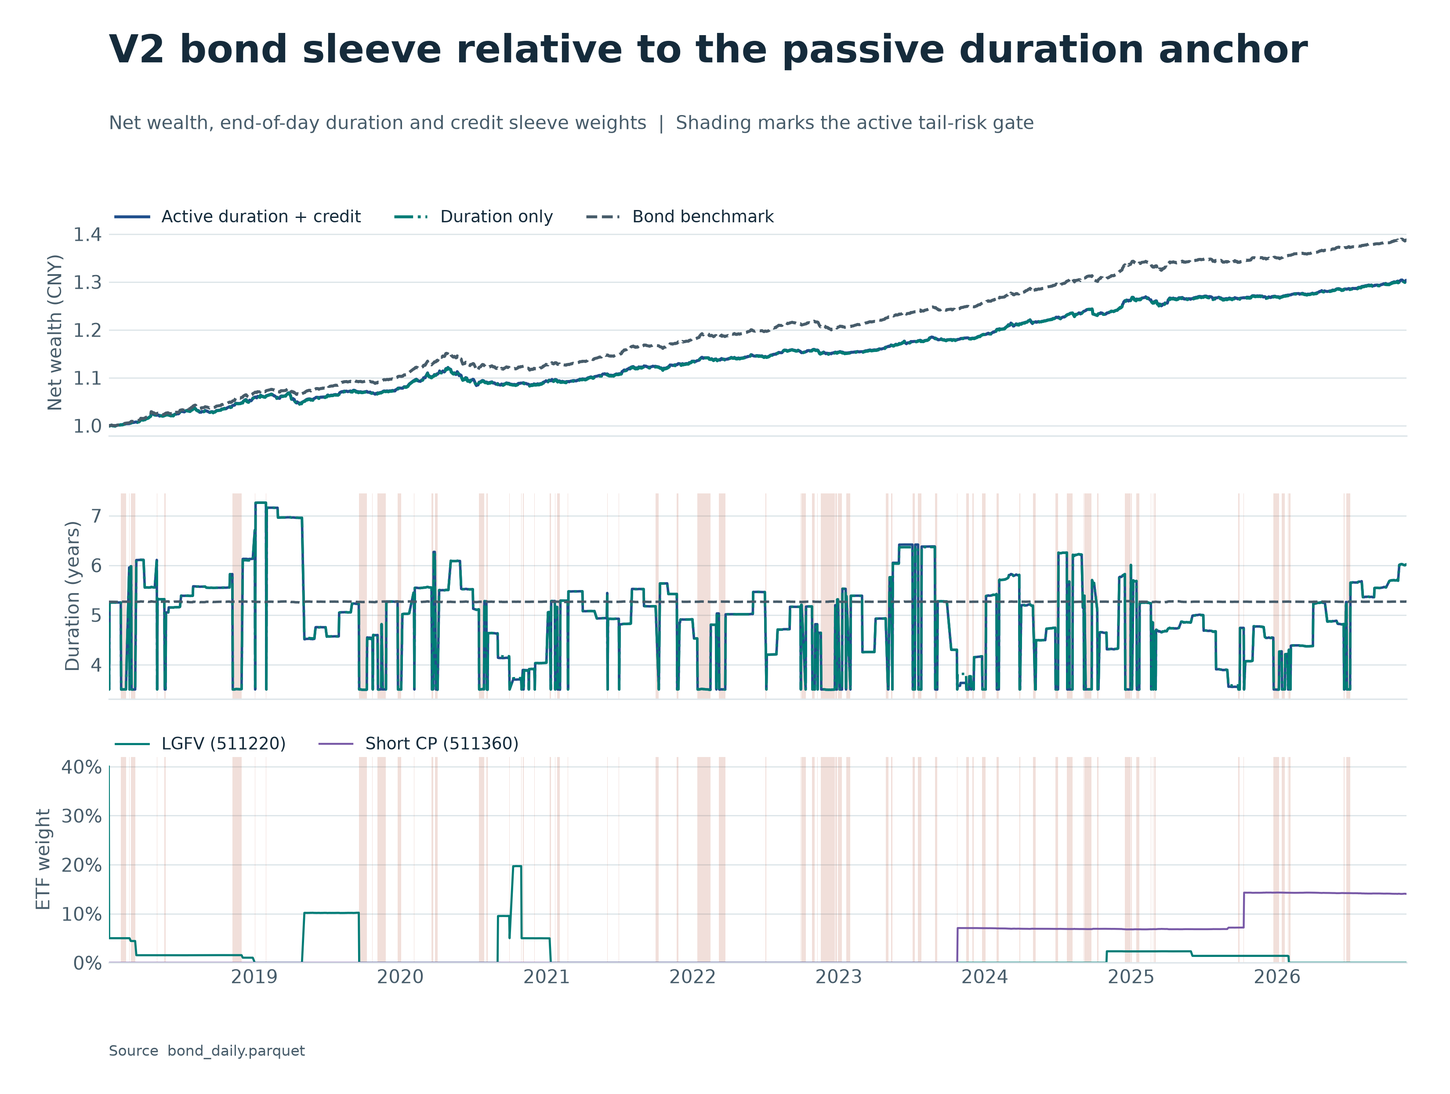

,cagr,sharpe,calmar,max_drawdown
strategy,,,,
Bond_Active_Sleeve,3.15%,1.01,0.93,-3.39%
Bond_Duration_Only,3.13%,0.99,0.92,-3.41%
Bond_Benchmark,3.90%,1.73,1.20,-3.25%


,Redemption window net return (2022-11-01 to 2022-12-15)
strategy,
Bond_Active_Sleeve,-0.70%
Bond_Benchmark,-1.39%
Bond_Duration_Only,-0.74%


In [5]:
curve_checks = pd.Series({
    "PCA first three components, calibration share": f"{meta['bond_curve_pca_fit_share_first_3']:.2%}",
    "PCA first three components, projected OOS share": f"{meta['bond_curve_pca_oos_projected_share_first_3']:.2%}",
    "Median DNS RMSE, OOS (bp)": f"{meta['dns_median_rmse_bps_oos']:.2f}",
})
display(curve_checks.to_frame("Estimate"))
display(read("bond_theoretical_tracking").style.hide(axis="index").format({
    "correlation": "{:.2f}", "mean_daily_residual_bps": "{:.2f}",
    "annualized_tracking_residual": "{:.2%}",
}, na_rep="—"))
show_figure("dns")
show_figure("bond")

bond_perf = read("bond_performance", index_col="strategy")
bond_models = ["Bond_Active_Sleeve", "Bond_Duration_Only", "Bond_Benchmark"]
bond_formats = {"cagr": "{:.2%}", "sharpe": "{:.2f}", "calmar": "{:.2f}", "max_drawdown": "{:.2%}"}
display(bond_perf.loc[bond_models, list(bond_formats)].style.format(bond_formats))

bond_daily = pd.read_parquet(outputs / "bond_daily.parquet")
window = read("stress_tests", parse_dates=["start", "end"]).query("event == 'redemption_2022'").iloc[0]
start, end = window[["start", "end"]]
redemption = bond_daily.loc[
    pd.to_datetime(bond_daily["date"]).between(start, end) & bond_daily["strategy"].isin(bond_models)
]
redemption_return = redemption.groupby("strategy")["net_return"].agg(lambda series: (1 + series).prod() - 1)
display(redemption_return.rename(f"Redemption window net return ({start:%Y-%m-%d} to {end:%Y-%m-%d})").to_frame().style.format("{:.2%}"))

## 5. Attribution and layer-by-layer changes

Brinson–Hood–Beebower decomposes daily active return into allocation, selection and interaction. Incremental implementation costs appear as a separate effect. Carino linking reconciles the daily effects to the cumulative and annualized arithmetic return gaps. The ablation table isolates the incremental effect of each research layer in the chosen order.

,annualized (bp),cumulative (bp)
effect,,
asset_allocation,+24.26,+278.87
equity_selection,+104.06,+1196.36
fixed_income_selection,-42.98,-494.15
cash_implementation,+0.00,+0.00
interaction,-14.47,-166.40
transaction_cost_drag,-30.07,-345.69
active_total,+40.79,+468.99
reconciliation_residual,+0.00,+0.00


,cagr,delta_cagr,sharpe,delta_sharpe,max_drawdown
strategy,,,,,
Static_20_80,3.79%,—,0.58,—,-4.51%
Macro_BL_Passive,4.01%,+0.22%,0.65,+0.07,-3.75%
Macro_BL_Bond_Active,3.40%,-0.61%,0.49,-0.16,-3.85%
Macro_BL_Equity_Bond_Active,4.38%,+0.98%,0.79,+0.30,-4.55%
Macro_BL_FixedIncomePlus,4.20%,-0.18%,0.76,-0.03,-3.93%
Macro_BL_Satellites,5.14%,+0.93%,1.03,+0.27,-3.91%


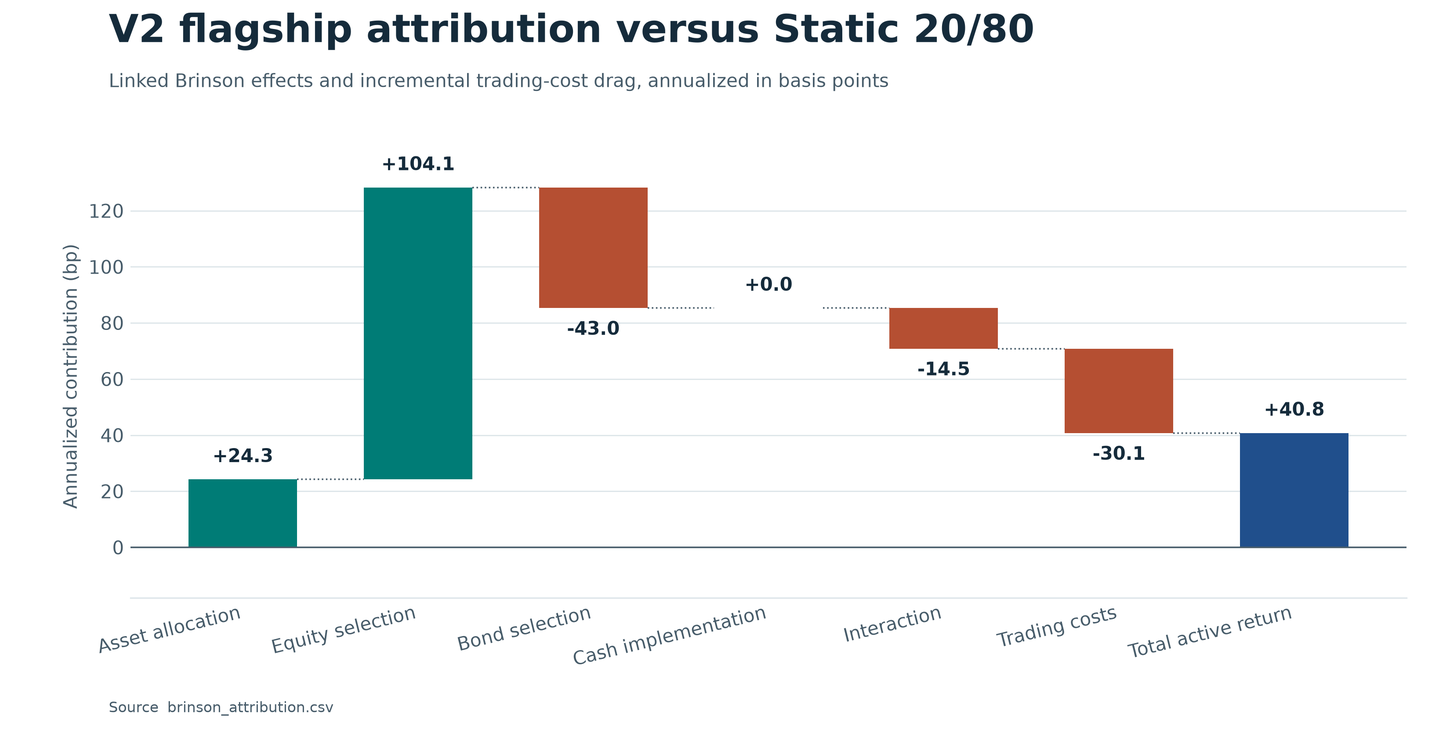

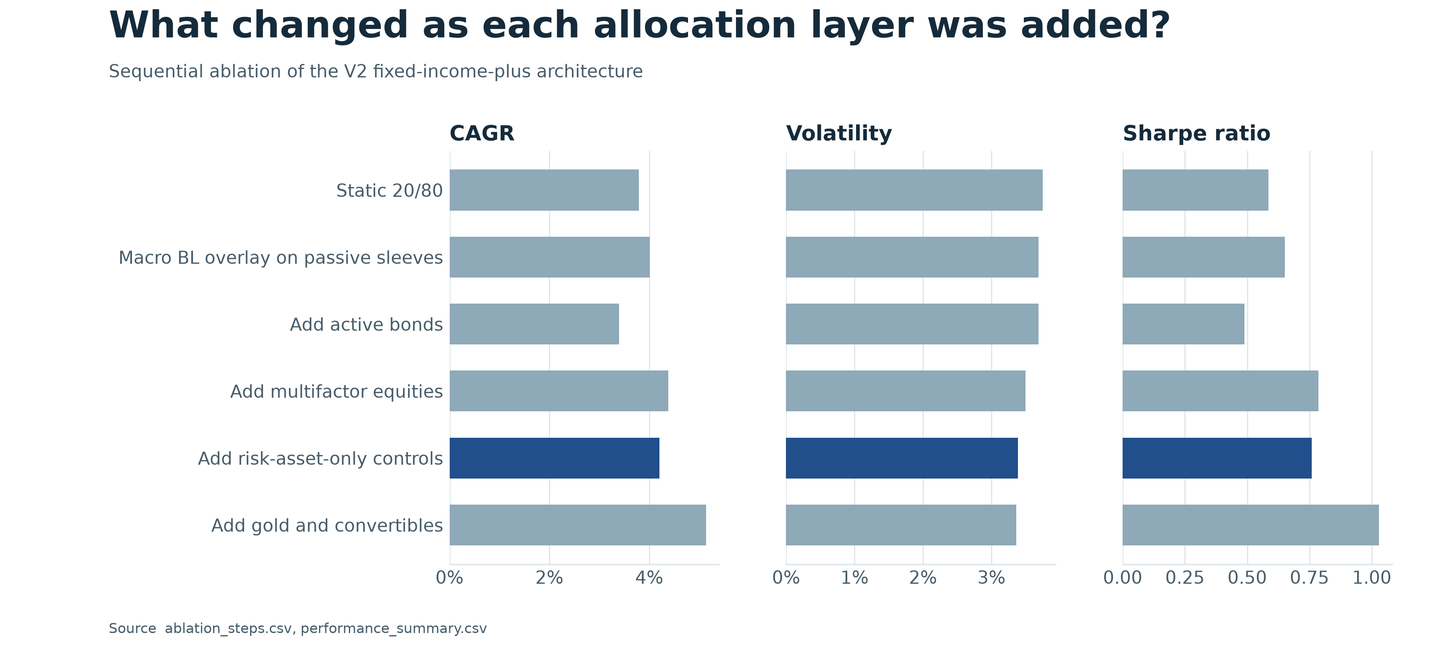

,V1 (bp),V2 (bp),V2 minus V1 (bp)
asset_allocation,-162.45,+24.26,+186.70
equity_selection,+52.90,+104.06,+51.16
fixed_income_selection,-73.43,-42.98,+30.45
cash_implementation,+0.00,+0.00,-0.00
interaction,+56.80,-14.47,-71.28
transaction_cost_drag,-36.89,-30.07,+6.82
active_total,-163.07,+40.79,+203.86
reconciliation_residual,+0.00,+0.00,-0.00


In [6]:
attribution = read("brinson_attribution", index_col="effect")
display(attribution.mul(10_000).rename(columns=lambda col: col + " (bp)").style.format("{:+.2f}"))
ablation = read("ablation_summary").set_index("strategy")
abl_formats = {"cagr": "{:.2%}", "delta_cagr": "{:+.2%}", "sharpe": "{:.2f}",
               "delta_sharpe": "{:+.2f}", "max_drawdown": "{:.2%}"}
display(ablation.loc[:, list(abl_formats)].style.format(abl_formats, na_rep="—"))
show_figure("brinson")
show_figure("ablation")

v1_attribution = pd.DataFrame.from_dict(v1["brinson"], orient="index")
attribution_compare = pd.concat([
    v1_attribution["annualized"].rename("V1 (bp)"),
    attribution["annualized"].rename("V2 (bp)"),
], axis=1).mul(10_000)
attribution_compare["V2 minus V1 (bp)"] = attribution_compare["V2 (bp)"] - attribution_compare["V1 (bp)"]
display(attribution_compare.style.format("{:+.2f}"))

## 6. Historical stress and parameter sensitivity

The stress exhibit uses realized returns on each historical path. Within a window, maximum drawdown resets its starting wealth immediately before the first included session. The Black–Litterman grid records the realized results of parameter perturbations over the same period. Treat these as sensitivity diagnostics when assessing the stability of the design.

strategy,Macro_BL_FixedIncomePlus,Static_20_80
event,,
bond_bear_2020,3.60%,3.08%
covid_q1_2020,0.56%,0.42%
deleveraging_2018,0.91%,-0.35%
low_rate_2025_26,5.13%,4.35%
redemption_2022,1.78%,1.25%
reversal_2024,3.70%,4.24%
stocks_bonds_2022,-0.80%,-2.52%


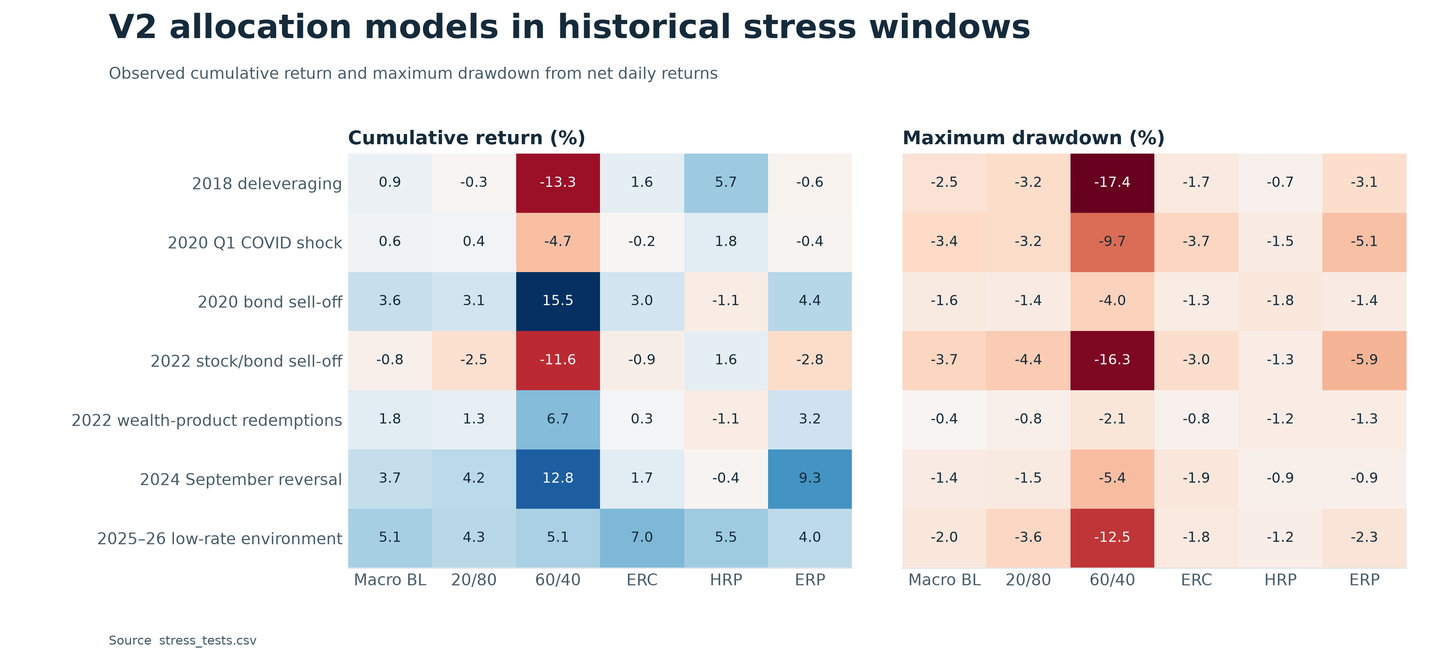

layer,cost_multiplier,strategy,cagr,sharpe,max_drawdown,annualized_cost_bps
allocation,0.500000,Allocation_Cost_0.5x,4.37%,0.81,-3.92%,14.9
allocation,1.000000,Macro_BL_FixedIncomePlus,4.20%,0.76,-3.93%,29.9
allocation,2.000000,Allocation_Cost_2x,3.88%,0.67,-3.98%,59.7
equity,0.500000,Equity_Cost_0.5x,6.84%,0.37,-31.86%,29.8
equity,1.000000,Equity_Alpha_Sleeve,6.52%,0.36,-32.17%,59.6
equity,2.000000,Equity_Cost_2x,5.89%,0.32,-32.76%,119.2
bond,0.500000,Bond_Active_Cost_0.5x,3.26%,1.09,-3.39%,11.0
bond,1.000000,Bond_Active_Sleeve,3.15%,1.01,-3.39%,22.0
bond,2.000000,Bond_Active_Cost_2x,2.92%,0.87,-3.48%,44.0


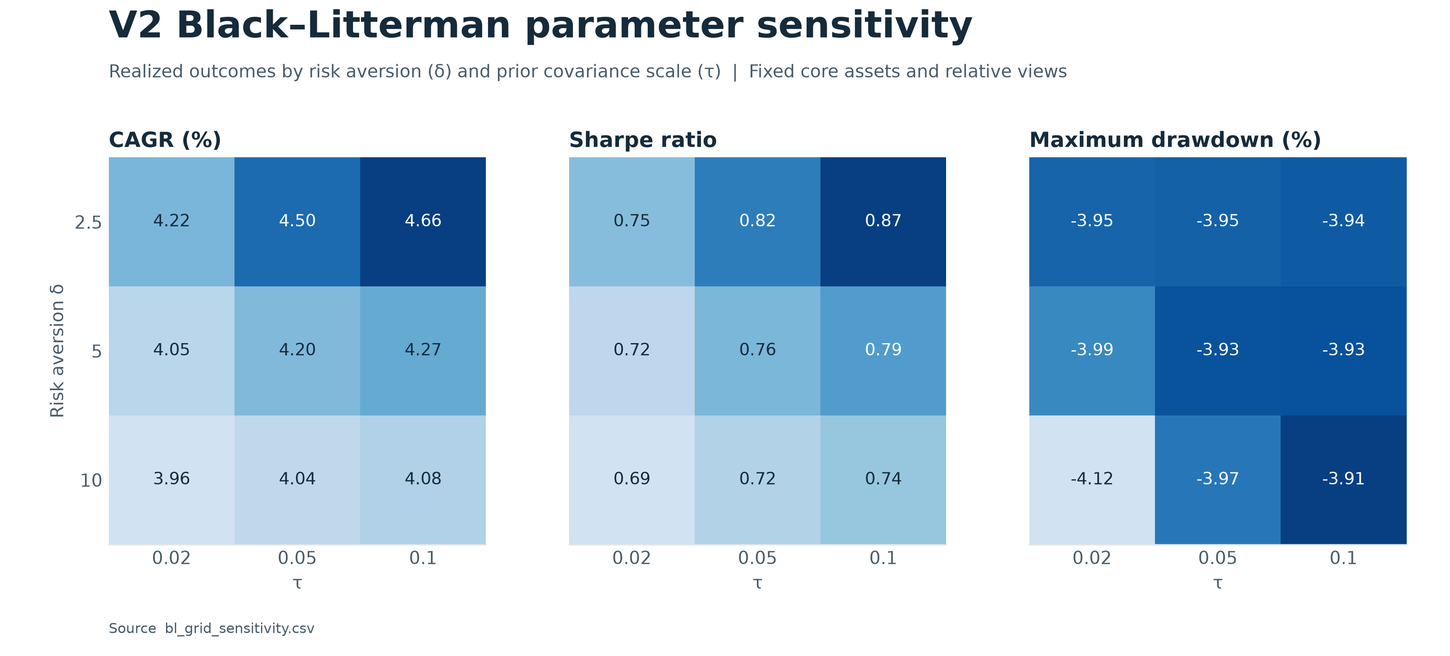

In [7]:
stress = read("stress_tests")
selection = stress.loc[stress["strategy"].isin([benchmark, flagship])]
display(selection.pivot(index="event", columns="strategy", values="cumulative_return").style.format("{:.2%}"))
show_figure("stress")

cost = read("cost_sensitivity")
display(cost.style.hide(axis="index").format({
    "cagr": "{:.2%}", "sharpe": "{:.2f}", "max_drawdown": "{:.2%}",
    "annualized_cost_bps": "{:.1f}",
}))
show_figure("bl")

## 7. Reconciliation checks

The checks below cross-reference independently stored results. The test suite in the repository covers the underlying point-in-time and execution assumptions.

The checks use saved research results. Causal re-runs and rolling overlay recovery are tested in the repository's pytest suite. The static industry proxy remains a retrospective data limitation even when those implementation tests pass.

In [8]:
daily = pd.read_parquet(outputs / "allocation_daily.parquet")
daily = daily.loc[daily["strategy"].eq(flagship)].set_index("date").sort_index()
weights = pd.read_parquet(outputs / "allocation_weights_end.parquet")
weights = weights.loc[weights["strategy"].eq(flagship)]
weight_cols = ["equity_etf", "equity_active", "bond_passive", "bond_active",
               "cash", "_cash", "gold", "convertible"]

np.testing.assert_allclose(weights[weight_cols].sum(axis=1), 1, rtol=0, atol=1e-9)
np.testing.assert_allclose((1 + daily["net_return"]).cumprod(), daily["nav"],
                           rtol=0, atol=1e-10)
np.testing.assert_allclose(study_months[prob_cols].sum(axis=1), 1, rtol=0, atol=1e-10)
cagr_excess = performance.loc[flagship, "cagr"] - performance.loc[benchmark, "cagr"]
np.testing.assert_allclose(attribution.loc["active_total", "annualized"],
                           cagr_excess, rtol=0, atol=1e-10)
residual_bps = attribution.loc["reconciliation_residual", "annualized"] * 10_000

assert abs(residual_bps) < 1
assert not industry.empty
assert industry["abs_deviation"].max() <= 0.04 + 1e-4
assert industry["executed_abs_deviation"].max() <= 0.04 + 1e-4
np.testing.assert_allclose(
    industry["executed_weight"].sub(industry["benchmark_weight"]).abs(),
    industry["executed_abs_deviation"], rtol=0, atol=1e-10,
)
np.testing.assert_allclose(
    industry["target_weight"].sub(industry["benchmark_weight"]).abs(),
    industry["abs_deviation"], rtol=0, atol=1e-10,
)
np.testing.assert_allclose(ensemble[ensemble_cols].sum(axis=1), 1, rtol=0, atol=1e-10)
assert ensemble[ensemble_cols].ge(0).all().all()
for _, observed in ensemble.filter(like="ensemble_latest_label_end_").items():
    label_end = pd.to_datetime(observed.dropna())
    assert (label_end <= label_end.index).all()
audit = json.loads((outputs / "raw_audit.json").read_text(encoding="utf-8"))
assert audit["manifest_files_match"]
assert audit["industry_model_provenance"]["static_proxy_enabled"]
assert not audit["industry_model_provenance"]["static_proxy_is_point_in_time"]
assert exposure.loc["cash", "top_level"] < 0.50
flagship_orders = read("allocation_orders").query("strategy == @flagship")
assert not flagship_orders.empty
core_orders = flagship_orders.loc[flagship_orders["reason"].eq("monthly")]
assert not core_orders.empty
np.testing.assert_allclose(core_orders["core_cash_target"], 0, rtol=0, atol=1e-12)
np.testing.assert_allclose(core_orders["core_weight_sum"], 1, rtol=0, atol=1e-8)
np.testing.assert_allclose(core_orders["relative_view_max_row_sum"], 0, rtol=0, atol=1e-12)
assert (daily["trailing_drawdown"] <= daily["drawdown"] + 1e-10).all()
print(f"Checks passed for {len(daily):,} flagship sessions and {len(industry):,} sector target and execution checks. "
      f"Annualized attribution residual: {residual_bps:.6f} bp.")

Checks passed for 2,155 flagship sessions and 7,167 sector target and execution checks. Annualized attribution residual: 0.000000 bp.
